In [78]:
from __future__ import annotations

import argparse
import os

import pandas as pd
import numpy as np
import torch
import torch.multiprocessing as mp
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions.normal import Normal

import gymnasium as gym
import matplotlib.pyplot as plt
import seaborn as sns




In [79]:
N_WORKERS = 4         
VALUE_COEF = 0.5
ENTROPY_COEF = 1e-3
GAMMA = 0.99
LEARNING_RATE = 1e-4
EPS = 1e-6

In [80]:
class ActorCritic(nn.Module):
    """Shared-trunk actor-critic network: Gaussian policy head + value head."""

    def __init__(self, obs_space_dims: int, action_space_dims: int):
        super().__init__()

        hidden_space1 = 16
        hidden_space2 = 32

        self.shared_net = nn.Sequential(
            nn.Linear(obs_space_dims, hidden_space1),
            nn.Tanh(),
            nn.Linear(hidden_space1, hidden_space2),
            nn.Tanh(),
        )

        self.policy_mean_net = nn.Sequential(nn.Linear(hidden_space2, action_space_dims))
        self.policy_stddev_net = nn.Sequential(nn.Linear(hidden_space2, action_space_dims))
        self.value_net = nn.Sequential(nn.Linear(hidden_space2, 1))

    def forward(self, x: torch.Tensor):
        shared_features = self.shared_net(x.float())

        action_means = self.policy_mean_net(shared_features)
        action_stddevs = torch.log(1 + torch.exp(self.policy_stddev_net(shared_features)))
        value = self.value_net(shared_features).squeeze(dim=-1)

        return action_means, action_stddevs, value

In [81]:
class SharedAdam(torch.optim.Adam):
    """Adam optimizer whose per-parameter state lives in shared memory,
    so multiple processes can update it concurrently."""

    def __init__(self, params, lr=1e-4, betas=(0.9, 0.999), eps=1e-8, weight_decay=0):
        super().__init__(params, lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, foreach=False, fused=False)
        for group in self.param_groups:
            for p in group["params"]:
                state = self.state[p]
                state["step"] = torch.zeros(1)
                state["exp_avg"] = torch.zeros_like(p.data)
                state["exp_avg_sq"] = torch.zeros_like(p.data)
                state["exp_avg"].share_memory_()
                state["exp_avg_sq"].share_memory_()
                state["step"].share_memory_()

In [82]:
def sync_local_from_global(local_net: ActorCritic, global_net: ActorCritic):
    local_net.load_state_dict(global_net.state_dict())


def push_grads_to_global(local_net: ActorCritic, global_net: ActorCritic):
    for local_param, global_param in zip(local_net.parameters(), global_net.parameters()):
        global_param._grad = local_param.grad

In [83]:

def worker(
    worker_id: int,
    seed: int,
    global_net: ActorCritic,
    optimizer: SharedAdam,
    episode_counter: mp.Value,
    episode_lock: mp.Lock,
    total_num_episodes: int,
    reward_log: list,  # a Manager().list() shared across processes
    obs_space_dims: int,
    action_space_dims: int,
):
    """Single asynchronous actor-learner loop (one A3C worker)."""

    # Deterministic-but-distinct seeding per worker
    worker_seed = seed * 1000 + worker_id
    torch.manual_seed(worker_seed)
    np.random.seed(worker_seed)

    env = gym.make("InvertedPendulum-v4")
    wrapped_env = gym.wrappers.RecordEpisodeStatistics(env, 50)

    local_net = ActorCritic(obs_space_dims, action_space_dims)

    while True:
        # Stop condition: global episode budget reached
        with episode_lock:
            if episode_counter.value >= total_num_episodes:
                break
            my_episode_index = episode_counter.value
            episode_counter.value += 1

        sync_local_from_global(local_net, global_net)

        obs, info = wrapped_env.reset(seed=worker_seed + my_episode_index)

        log_probs = []
        values = []
        entropies = []
        rewards = []

        done = False
        while not done:
            state = torch.tensor(np.array([obs]))
            action_means, action_stddevs, value = local_net(state)

            distrib = Normal(action_means[0] + EPS, action_stddevs[0] + EPS)
            action = distrib.sample()
            log_prob = distrib.log_prob(action)
            entropy = distrib.entropy()

            obs, reward, terminated, truncated, info = wrapped_env.step(action.numpy())
            done = terminated or truncated

            log_probs.append(log_prob)
            values.append(value)
            entropies.append(entropy)
            rewards.append(reward)

        # ---- Compute full-episode Monte-Carlo returns (A3C n-step with n = T) ----
        running_g = 0.0
        gs = []
        for r in rewards[::-1]:
            running_g = r + GAMMA * running_g
            gs.insert(0, running_g)
        returns = torch.tensor(gs, dtype=torch.float32)

        values_t = torch.stack(values).squeeze()
        log_probs_t = torch.stack(log_probs).squeeze()
        entropies_t = torch.stack(entropies).squeeze()

        advantages = returns - values_t

        policy_loss = -torch.sum(log_probs_t * advantages.detach()) - ENTROPY_COEF * torch.sum(entropies_t)
        value_loss = torch.sum(advantages.pow(2))
        loss = policy_loss + VALUE_COEF * value_loss

        local_net.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(local_net.parameters(), max_norm=40.0)

        push_grads_to_global(local_net, global_net)
        optimizer.step()

        episode_reward = wrapped_env.return_queue[-1]
        reward_log.append((my_episode_index, float(episode_reward[0]) if hasattr(episode_reward, "__len__") else float(episode_reward)))

        if my_episode_index % 1000 == 0:
            print(f"[A3C][seed {seed}][worker {worker_id}] global episode {my_episode_index}, reward {episode_reward}")

    wrapped_env.close()

In [84]:
def run_single_seed(seed: int, total_num_episodes: int, obs_space_dims: int, action_space_dims: int):
    global_net = ActorCritic(obs_space_dims, action_space_dims)
    global_net.share_memory()

    optimizer = SharedAdam(global_net.parameters(), lr=LEARNING_RATE)

    manager = mp.Manager()
    reward_log = manager.list()
    episode_counter = mp.Value("i", 0)
    episode_lock = mp.Lock()

    processes = []
    for worker_id in range(N_WORKERS):
        p = mp.Process(
            target=worker,
            args=(
                worker_id,
                seed,
                global_net,
                optimizer,
                episode_counter,
                episode_lock,
                total_num_episodes,
                reward_log,
                obs_space_dims,
                action_space_dims,
            ),
        )
        p.start()
        processes.append(p)

    for p in processes:
        p.join()

    # Sort recorded (episode_index, reward) pairs by episode index so the
    # resulting curve is directly comparable to the sequential algorithms.
    results = sorted(list(reward_log), key=lambda pair: pair[0])
    reward_over_episodes = [r for _, r in results]
    return reward_over_episodes

In [85]:
def run(total_num_episodes, seeds):
    out_dir = "../results"
    plot_dir = f"{out_dir}/plots"
    os.makedirs(out_dir, exist_ok=True)
    os.makedirs(plot_dir, exist_ok=True)

    env = gym.make("InvertedPendulum-v5")
    obs_space_dims = env.observation_space.shape[0]
    action_space_dims = env.action_space.shape[0]
    env.close()

    rewards_over_seeds = []

    for seed in seeds:
        torch.manual_seed(seed)
        np.random.seed(seed)

        reward_over_episodes = run_single_seed(seed, total_num_episodes, obs_space_dims, action_space_dims)
        rewards_over_seeds.append(reward_over_episodes)

        np.save(os.path.join(out_dir, f"a3c_seed{seed}.npy"),
                np.array(reward_over_episodes, dtype=np.float32))

    np.save(os.path.join(out_dir, "a3c_all_seeds.npy"), np.array(rewards_over_seeds, dtype=np.float32))

    df = pd.DataFrame(rewards_over_seeds).melt()
    df.rename(columns={"variable": "episodes", "value": "reward"}, inplace=True)

    sns.set(style="darkgrid", context="talk", palette="rainbow")
    plt.figure(figsize=(10, 6))
    
    # Lineplot automatically calculates standard error bands around the seed mean
    ax = sns.lineplot(x="episodes", y="reward", data=df)
    ax.set(title="A3C (Asynchronous Advantage Actor-Critic) for InvertedPendulum-v5")
    
    # Save image version to results directory
    plt.savefig(os.path.join(plot_dir, "a3c_learning_curve.png"))
    print(f"Success! Saved training image to: {plot_dir}")
    
    plt.show()

    return rewards_over_seeds

Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: Can't get attribute 'worker' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>
Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/spawn.py", line 13

Success! Saved training image to: ../results/plots


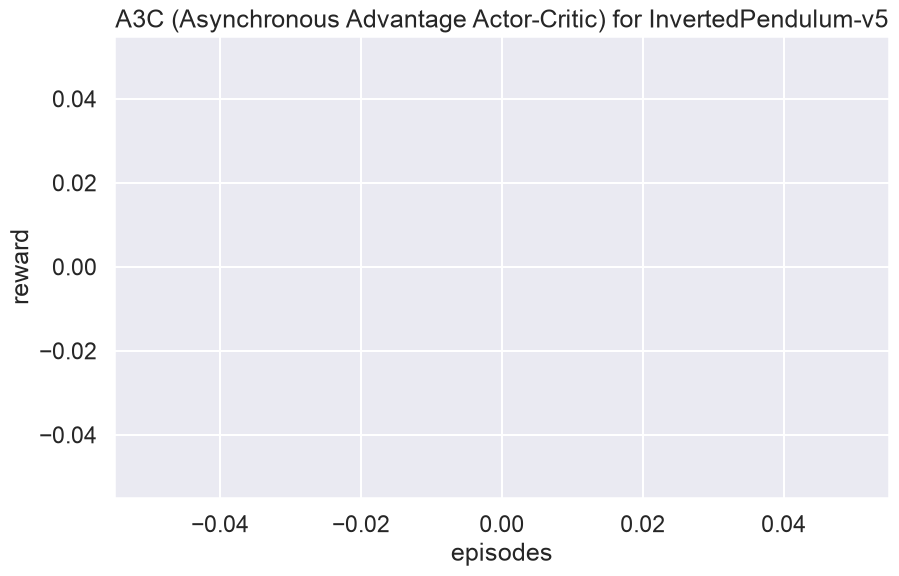

In [86]:
results = run(total_num_episodes=5000, seeds=(1, 2, 3, 5, 8))